In [1]:
import warnings
warnings.filterwarnings('ignore')

import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import cmocean.cm as cmo
import numpy as np

from utils import make_map, subplots_structure, get_shelf_edge

In [2]:
def add_observation_locations(ax, timerange, sanagu=False, argo=False, glider=False):
    
    if sanagu:
        locs = pd.read_csv(sanagu, index_col=0)
        ax.scatter(locs['lon'], locs['lat'], c='tab:blue', s=100)
        
    if glider:
        # loading glider track
        ds = xr.open_dataset(glider)

        ds = ds.sel(time=slice(timerange[0], timerange[1]))
        
        ax.scatter(ds['longitude'], ds['latitude'], color='k', zorder=10, s=100)
        
    if argo:
        # loading ARGO profiles
        lista = []
        for f in argo:
            ds_ = xr.open_dataset(f)
            ds_ = ds_.where(ds_argo1['TIME'] <= timerange[1], drop=True)
            lista.append(ds_)
        
        ds_argo = xr.concat(lista, dim='N_PROF')
        ax.scatter(ds_argo['LONGITUDE'], ds_argo['LATITUDE'], color='r', zorder=11, s=100)
        
    return ax

In [3]:
timerange = [pd.to_datetime('2022-03-01'), 
             pd.to_datetime('2022-04-01')]

zoomed_extent= [-45, -39, -27, -22]

In [4]:
bathy = xr.open_dataset('../data/gebco_2019.nc')
# rename variables for a padronization
bathy = bathy.rename({'elevation': 'depth'})
bathy = bathy.where(bathy['depth'] < 0, drop=True)

# regional selection (for both dataset loaded)
lon_lower, lon_upper = zoomed_extent[0], zoomed_extent[1] #-50, -40
lat_lower, lat_upper = zoomed_extent[2], zoomed_extent[3] #-29, -23

# bathymetry
bathy = bathy.sel(lon=slice(lon_lower, lon_upper),
                lat=slice(lat_lower, lat_upper))

# lagrangian releasing points
north = [-40, -22]
east = [-39, -26.5]

In [5]:
# loading SANAGU dataset
locs = pd.read_csv(f"/home/danilo/phd/thesis/chapter_colab/scripts/section-ctd_dalton/data/umassd2/locations.csv", index_col=0)
locs.head()

,lon,lat,time
SANAGU12_F1_CTD_1_OT,-44.094500,-23.256667,2022-02-13 10:37:16
SANAGU12_F1_LISST_DEEP_CTD_1_OT,-44.094500,-23.256667,2022-02-13 12:04:04
SANAGU12_F2_CTD_1_OT,-43.921167,-23.592667,2022-02-13 17:23:17
SANAGU12_F2_LISST_DEEP_CTD_1_OT,-43.921167,-23.592667,2022-02-13 18:56:31
SANAGU12_F3_CTD_1_OT,-43.767333,-23.893000,2022-02-14 10:53:56


In [6]:
# loading glider track
ds = xr.open_dataset(f"../data/glider/sg576_Azul_19")

ds = ds.sel(time=slice(timerange[0], timerange[1]))
ds

<xarray.Dataset>
Dimensions:           (update: 1, time_raw: 540700, variables: 6, time: 132,
                       depth: 46)
Coordinates:
  * update            (update) int32 0
  * time              (time) datetime64[ns] 2022-03-01T05:25:18.500000 ... 20...
  * time_raw          (time_raw) datetime64[ns] 2021-11-22T11:32:30 ... 2022-...
  * depth             (depth) float32 5.0 10.0 15.0 20.0 ... 900.0 950.0 1e+03
Dimensions without coordinates: variables
Data variables: (12/26)
    qc                (time_raw, variables) int32 ...
    dive_start        (time) int32 ...
    dive_end          (time) int32 ...
    start_date        (time) datetime64[ns] ...
    end_date          (time) datetime64[ns] ...
    down_up           (time_raw) int32 ...
    ...                ...
    chlorophyll       (time, depth) float32 ...
    chlorophyll_raw   (time_raw) float32 ...
    cdom              (time, depth) float32 ...
    cdom_raw          (time_raw) float32 ...
    DAC               (time) float32 ...
    DAC_DIR           (time) float32 ...
Attributes:
    title:            Glider Data
    glider_id:        576
    julian_day_unit:  seconds since 1970-01-01 00:00:00 UTC
    _FillValue:       -9999.9999

In [7]:
ds_argo = xr.open_dataset('../data/argo/argo_profiles_all.nc')

# splitting argo into two dataset for platform numbers 3901225 and 3902154
ds_argo1 = ds_argo.where(ds_argo['PLATFORM_NUMBER'] == 3901549, drop=True)
ds_argo2 = ds_argo.where(ds_argo['PLATFORM_NUMBER'] == 3901225, drop=True)

In [8]:
set(ds_argo['PLATFORM_NUMBER'].values)

{3901225, 3901549, 3902154, 3902399}

In [9]:
dfGDP = pd.read_csv('../data/drifter_6hour_qc_9876_f318_a578.csv', header=0)
dfGDP = dfGDP.iloc[1:]

dfGDP['longitude'] = dfGDP['longitude'].astype(float)
dfGDP['latitude'] = dfGDP['latitude'].astype(float)

In [10]:
# alongshelf transect
import json

with open('alongshelf_transect.json', 'r') as f:
    alongshelf_transect = json.load(f)
    
alongshelf_transect.keys()

dict_keys(['lats', 'lons'])

In [11]:
def insert_miniglobe(ax,fig,loc,extent=[-50,-41,-30,-22],center=[-45,-15]):
    import cartopy.crs as ccrs
    from matplotlib.patheffects import Stroke
    import shapely.geometry as sgeom
    import cartopy.feature as cfeature
    
    # if loc == 'upper left':
    #     location = [0.13, 0.642, 0.2, 0.15]
    # elif loc == 'lower right':
    #     location = [0.7, 0.18, 0.2, 0.2]
    location = loc

    sub_ax = fig.add_axes(location,projection=ccrs.Orthographic(center[0],center[1]))

    # # Make a nice border around the inset axes.
    # effect = Stroke(linewidth=.1, foreground='black', alpha=0.5)
    # sub_ax.outline_patch.set_path_effects([effect])

    # Add the land, coastlines and the extent of the Brazil.
    # draw coastlines and borders
    sub_ax.add_feature(cfeature.COASTLINE, lw=0.0001)
    sub_ax.add_feature(cfeature.BORDERS, lw=0.00001)

    # draw meridians and parallels
    gl = ax.gridlines(color='k', linestyle=(0, (1, 1)),
                      xlocs=range(0, 390, 30),
                      ylocs=[-80, -60, -30, 0, 30, 60, 80])

    sub_ax.add_feature(cfeature.LAND,linewidth=0.0001)
    sub_ax.coastlines(linewidth=0.00001)
    sub_ax.stock_img()

    extent_box = sgeom.box(extent[0], extent[2], extent[1], extent[3])
    sub_ax.add_geometries([extent_box], ccrs.PlateCarree(), facecolor='bisque',
                          edgecolor='k', linewidth=1,alpha=.8)

    return sub_ax

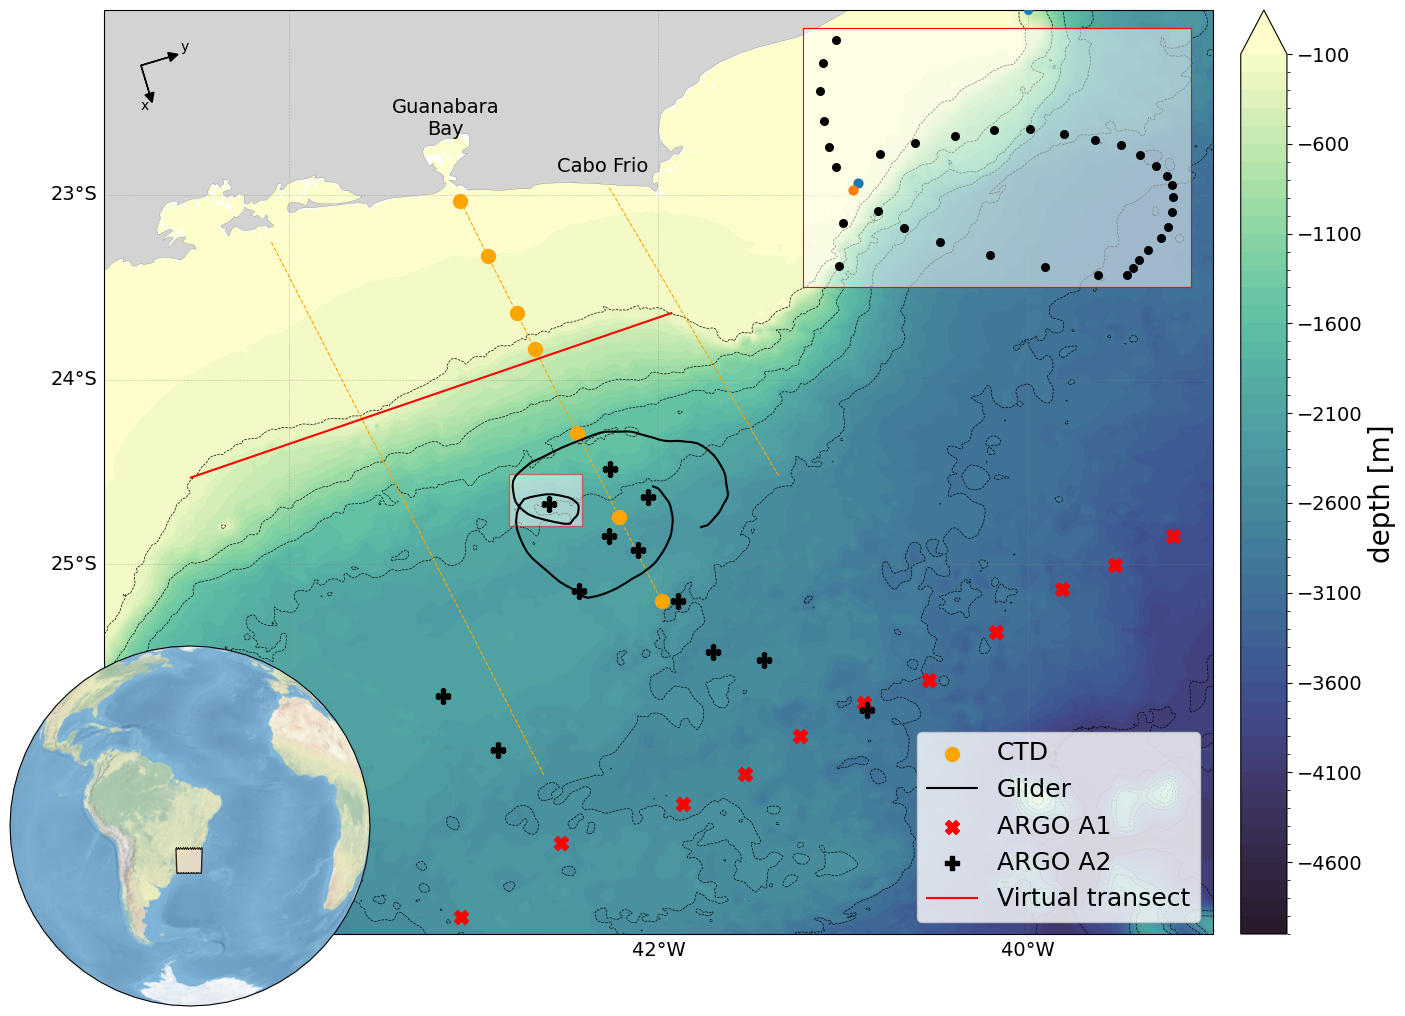

In [89]:
fig,axes = subplots_structure(1, 1, (18,12), 1)
ax = axes[0]
ax = make_map(ax=ax, facecolor='lightgray', deltax=2, deltay=1)
ax.set_extent(zoomed_extent)

# ax.plot(shelf['lon'], shelf['lat'], 'k--', lw=.5)
cr = bathy.depth.plot.contour(ax=ax,
                         levels=[-200, -1000, -1500, -2000, -2500, -3000, -4000, -5000], 
                         colors=('k'), linewidths=(0.5), linestyles=('--'))

cf = bathy.depth.plot.contourf(ax=ax, cmap=cmo.deep_r, levels=np.arange(-5000, 0, 100), add_colorbar=False)

cb = plt.colorbar(cf, pad=0.02)
cb.set_label(label='depth [m]', size='20')
cb.ax.tick_params(labelsize='14')

for pattern in ['_F', 'SANAGU15_G', 'SANAGU15_H']:
    ax.plot(locs[locs.index.str.contains(pattern)]['lon'], 
            locs[locs.index.str.contains(pattern)]['lat'], ls='--', lw=0.8, c='orange')

ax.scatter(locs[locs.index.str.contains('SANAGU15_G')]['lon'], 
           locs[locs.index.str.contains('SANAGU15_G')]['lat'], label="CTD", c='orange', 
           s=100, marker='o', zorder=10)

ax.plot(ds['longitude'], ds['latitude'], color='k', zorder=10, #s=40, 
           label='Glider')

ax.scatter(ds_argo1['LONGITUDE'], ds_argo1['LATITUDE'], color='r', 
           zorder=11, s=100, label='ARGO A1', marker="X")

ax.scatter(ds_argo2['LONGITUDE'], ds_argo2['LATITUDE'], color='k', 
           zorder=11, s=100, label='ARGO A2', marker="P")

ax.plot(alongshelf_transect['lons'], alongshelf_transect['lats'], 'r', label='Virtual transect')

# ax.scatter(dfGDP['longitude'], dfGDP['latitude'], color='g', zorder=12, s=40, 
#            label='GDP')

plt.legend(loc='lower right', fontsize=18)

## inserting mini globe
sub_ax = insert_miniglobe(ax, fig, loc=[0.0, 0.05, 0.4, 0.3], 
                          extent=[-50,-41,-30,-22],center=[-45,-15])

## plotting inner map
axins = inset_axes(ax, width="70%", height="70%",
                   bbox_to_anchor=(.63, .58, .5, .4),
                   bbox_transform=ax.transAxes, loc=2, borderpad=0)

axins.tick_params(left=False, right=False, labelleft=False, labelright=False, bottom=False, labelbottom=False, top=False, labeltop=False)
axins.set_ylabel('')
axins.set_xlabel('')
axins.set_facecolor("#FFF")
_ = [axins.spines[loc].set_color('red') for loc in ['left', 'bottom', 'right', 'top']]
axins.patch.set_alpha(0.5)

axins.scatter(ds.sel(time=slice('2022-03-12', '2022-03-19'))['longitude'], 
              ds.sel(time=slice('2022-03-12', '2022-03-19'))['latitude'], 
              color='k', zorder=10, s=30, label='Glider')

axins.scatter(ds.sel(time='2022-03-12 17:33')['longitude'], ds.sel(time='2022-03-12 17:33')['latitude'], 
            color='tab:blue', zorder=11, s=40)
axins.scatter(ds.sel(time='2022-03-18 13:24')['longitude'], ds.sel(time='2022-03-18 13:24')['latitude'], 
            color='tab:orange', zorder=11, s=40)

ax.indicate_inset_zoom(axins, edgecolor="red", facecolor='white')

# textual elements
ax.text(-42.3, -22.9, 'Cabo Frio', ha='center', va='bottom', fontsize=14)
ax.text(-43.15, -22.7, 'Guanabara\nBay', ha='center', va='bottom', fontsize=14)


ax.scatter(north[0], north[1], marker='o', s=30, zorder=20)
# ax.scatter(east[0], east[1], marker='o', s=30, zorder=20)

ax.arrow(-44.8, -22.3, .06, -0.2, length_includes_head=True, head_width=0.05, head_length=0.05, zorder=10, fc='k')
ax.arrow(-44.8, -22.3, .2, 0.06, length_includes_head=True, head_width=0.05, head_length=0.05, zorder=10, fc='k')
ax.text(-44.76, -22.52, "x", ha='right', va='center')
ax.text(-44.54, -22.2, "y", ha='right', va='center')

fig.patch.set_alpha(1.0)
plt.savefig('../figures/manuscript/00_manuscript_study_area.png', bbox_inches="tight", dpi=300)